In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Paths to dataset in Google Drive
train_dir = "/content/drive/MyDrive/abc/image_dataset/train"
test_dir = "/content/drive/MyDrive/abc/image_dataset/test"


Mounted at /content/drive


Found 10 files belonging to 2 classes.
Found 4 files belonging to 2 classes.


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 0.5000 - loss: 0.6849 - val_accuracy: 0.5000 - val_loss: 0.7513
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.5000 - loss: 0.7344 - val_accuracy: 0.5000 - val_loss: 0.6585
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.5000 - loss: 0.6283 - val_accuracy: 0.7500 - val_loss: 0.6481
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step - accuracy: 0.9000 - loss: 0.5980 - val_accuracy: 0.7500 - val_loss: 0.6198
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 313ms/step - accuracy: 0.9000 - loss: 0.5409 - val_accuracy: 1.0000 - val_loss: 0.5601
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step - accuracy: 1.0000 - loss: 0.4756 - val_accuracy: 1.0000 - val_loss: 0.5107
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 1.0000 - loss: 0.4157 - val_accuracy: 0.7500 - val_loss: 0.4703
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 311ms/step - accuracy: 0.9000 - loss: 0.3484 - val_accuracy: 0.7500 - val_loss: 0.

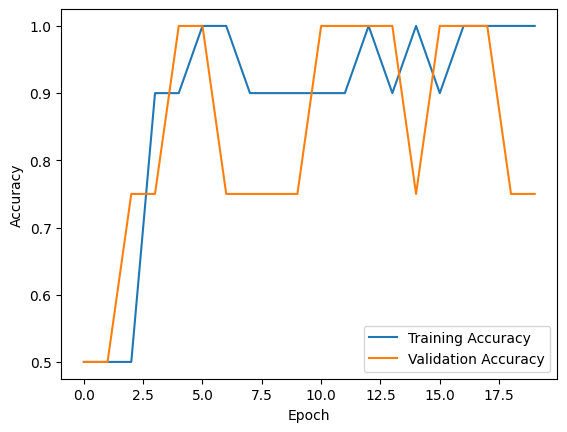

In [2]:
# Install TensorFlow (if needed)
#!pip install tensorflow matplotlib

# Import necessary libraries
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image_dataset_from_directory
import matplotlib.pyplot as plt

# Load datasets
batch_size = 32
img_size = (128, 128)  # Resize all images to this size

train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="int",
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=img_size,
    batch_size=batch_size,
    label_mode="int",
)

# Normalize pixel values to [0, 1]
normalization_layer = layers.Rescaling(1./255)
train_dataset = train_dataset.map(lambda x, y: (normalization_layer(x), y))
test_dataset = test_dataset.map(lambda x, y: (normalization_layer(x), y))

# Build the model
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(2, activation='softmax')  # Classes detected automatically
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
history = model.fit(train_dataset, epochs=20, validation_data=test_dataset)

# Evaluate the model
test_loss, test_acc = model.evaluate(test_dataset, verbose=2)
print(f"Test accuracy: {test_acc:.2f}")

# Plot training results
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
Predicted class: [[0.99246264 0.00753734]]


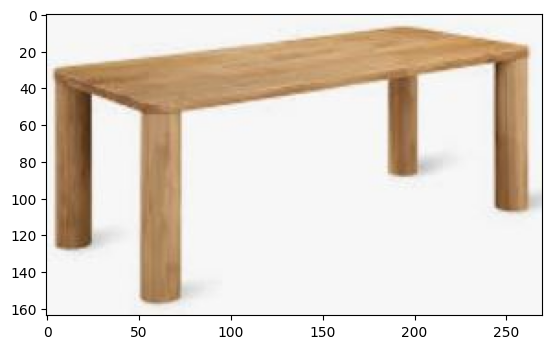

In [3]:
# Test the model on a single image
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# Load a test image from Google Drive
img_path = "/content/drive/MyDrive/abc/image_dataset/test/class1/image1.JPG"  # Update with your image path


img = mpimg.imread(img_path)# show image using two statements
plt.imshow(img)

img = load_img(img_path, target_size=img_size)
img_array = img_to_array(img) / 255.0
img_array = tf.expand_dims(img_array, axis=0)  # Add batch dimension

# Predict
predictions = model.predict(img_array)
print(f"Predicted class: {predictions}") # If first value if higher then class Table other wise Chair